# Two common mistakes, made on purpose

Our models score about 52% on next-day direction, which is a coin flip. Papers in this area often report 60-90%.
This notebook makes two common mistakes on purpose, to show what each one does to the score.

- **Data:** the development test years 2017-2022. The holdout isn't used.
- **Setup:** step 4's 12 technical indicators and five of its models (LDA is left out: it has no settings to tune).
- **Every score here except the "honest" ones is wrong on purpose.**

Finished runs are saved in `results/`, so a rerun is quick. The first run takes about 20 minutes.

In [1]:
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
from joblib import Parallel, delayed

from charts import bars, new_chart, reference_line, save
from classifiers import CLASSIFIERS, fit_classifier
from data import clean, load_all, read_market
from evaluation import TEST_YEARS
from features import make_indicators
from models import pooled, walk_forward
from test_leakage import assert_features_ignore_day_t

markets = load_all()  # development period only
MODELS = ["Logistic regression", "KNN", "SVM", "Random forest", "AdaBoost"]
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

def run_market(path, run, df):
    """Load the saved predictions, or run the model and save them."""
    if path.exists():
        return pd.read_pickle(path)
    preds = run(df)
    preds.to_pickle(path)
    return preds

def run_all_models(name, run_with):
    """One run per model and market, three markets at a time. run_with(settings) returns a function of df."""
    runs = {}
    for model in MODELS:
        run = run_with(CLASSIFIERS[model])
        by_market = Parallel(n_jobs=3)(
            delayed(run_market)(RESULTS / f"mistakes_{name}_{model}_{market}.pkl", run, df) for market, df in markets.items()
        )
        runs[model] = dict(zip(markets, by_market))
    return runs

def accuracy_table(runs):
    """Accuracy over all six test years, for each model (rows) and market (columns)."""
    return pd.DataFrame({model: {market: pooled(p)["accuracy %"] for market, p in by_market.items()}
                         for model, by_market in runs.items()}).T

def significantly_above(runs):
    """How many of the 30 model-market pairs beat the fair bar with p < 0.05."""
    scores = [pooled(p) for by_market in runs.values() for p in by_market.values()]
    return sum(s["accuracy %"] > s["fair bar %"] and s["p vs fair"] < 0.05 for s in scores)

## The honest version

Step 4's setup: day t's indicators use prices up to day t-1, and settings are picked on the tune year.

In [2]:
honest = run_all_models("honest", lambda settings: partial(walk_forward, fit=fit_classifier, grid=settings, make_x=make_indicators))

fair_bar = pd.Series({market: pooled(p)["fair bar %"] for market, p in honest["KNN"].items()}, name="fair bar %")
display(fair_bar.to_frame().T.round(1))
accuracy_table(honest).round(1)

,Indonesia,Malaysia,Philippines,Singapore,Thailand,India
fair bar %,52.9,49.8,51.8,49.4,52.4,54.6


,Indonesia,Malaysia,Philippines,Singapore,Thailand,India
Logistic regression,53.1,49.5,52.1,50.4,52.3,54.5
KNN,52.8,51.5,50.5,52.7,52.3,54.8
SVM,52.9,49.6,51.3,50.1,52.4,54.4
Random forest,52.3,49.0,51.8,52.8,53.2,53.3
AdaBoost,51.4,50.6,52.1,50.9,50.9,54.4


## Mistake 1: forgetting the one-day lag

We predict whether day t closes up. The indicators for day t must stop at day t-1.
Without the lag they use day t's own close, which is the answer itself.
For example, momentum becomes today's close minus the close four days ago.

The whole mistake is one missing `.shift(1)`:

In [3]:
def indicators_without_lag(df):
    """The mistake: day t's indicators use day t's own close."""
    return make_indicators(df).shift(-1)  # undoes the one-day lag that make_indicators ends with

no_lag = run_all_models("no_lag", lambda settings: partial(walk_forward, fit=fit_classifier, grid=settings, make_x=indicators_without_lag))
accuracy_table(no_lag).round(1)

,Indonesia,Malaysia,Philippines,Singapore,Thailand,India
Logistic regression,91.6,91.8,92.7,92.7,90.9,92.0
KNN,89.5,88.9,89.5,89.4,87.2,88.4
SVM,91.2,91.2,92.0,92.0,90.2,92.7
Random forest,89.9,90.5,90.5,91.2,89.3,91.4
AdaBoost,86.0,86.5,84.5,87.4,84.6,87.5


Which indicators give the answer away? Logistic regression on one indicator at a time, without the lag (accuracy in %):

In [4]:
def one_indicator(df, column):
    return indicators_without_lag(df)[[column]]

alone = {}
for column in make_indicators(markets["India"]).columns:
    alone[column] = {market: pooled(walk_forward(df, fit_classifier, CLASSIFIERS["Logistic regression"],
                                                 make_x=partial(one_indicator, column=column)))["accuracy %"]
                     for market, df in markets.items()}
alone = pd.DataFrame(alone).T
alone["mean"] = alone.mean(axis=1)
alone.sort_values("mean", ascending=False).round(1)

,Indonesia,Malaysia,Philippines,Singapore,Thailand,India,mean
ad_osc,85.4,85.5,85.0,87.0,84.8,86.4,85.7
disparity5,76.0,74.0,74.3,75.6,75.2,77.0,75.3
disparity10,67.1,67.3,66.0,67.7,67.3,69.0,67.4
stoch_k,66.4,65.6,65.5,66.3,66.8,67.1,66.3
williams_r,66.4,65.6,65.5,66.3,66.8,67.1,66.3
momentum,65.5,65.1,62.9,66.1,64.9,67.5,65.3
cci,63.3,62.7,61.4,64.2,64.7,64.6,63.5
rsi,59.8,59.8,58.2,61.8,60.5,61.2,60.2
roc,59.4,59.5,58.8,61.4,60.0,61.3,60.0
stoch_d,55.0,55.3,55.3,56.6,57.3,57.9,56.2


### The leakage test catches it

The test changes day t's own prices and checks that the features for day t stay the same.

In [5]:
raw = read_market("India")
day = pd.Timestamp("2018-06-29")

for name, make_x in {"with the lag": make_indicators, "without the lag": indicators_without_lag}.items():
    try:
        assert_features_ignore_day_t(lambda raw, market: make_x(clean(raw, market)), raw, "India", day, np.random.default_rng(0))
        print(f"{name}: passes")
    except AssertionError:
        print(f"{name}: CAUGHT - the features for day t change when day t's own prices change")

with the lag: passes
without the lag: CAUGHT - the features for day t change when day t's own prices change


## Mistake 2: tuning on the test year

The paper picked the SVM's settings and the network's hidden nodes by their score on the test period.
Here every model does the same: for each test year, try every setting and keep the one that scores best **on that same year**.

The features are honest in this one. Only the choice of setting has seen the answers.

In [6]:
def only_setting(fit, settings, *data):
    """Nothing to pick: there is one setting."""
    return settings[0]

def tuned_on_test_year(df, settings):
    """The mistake: for each test year, keep the setting that scores best on that same year."""
    runs = [walk_forward(df, fit_classifier, [setting], make_x=make_indicators, pick=only_setting) for setting in settings]
    best_years = []
    for year in TEST_YEARS:
        candidates = [p[p["year"] == year] for p in runs]
        best_years.append(max(candidates, key=lambda p: ((p["p_up"] > 0.5) == p["up"]).mean()))
    return pd.concat(best_years)

tuned = run_all_models("tuned_on_test", lambda settings: partial(tuned_on_test_year, settings=settings))
accuracy_table(tuned).round(1)

,Indonesia,Malaysia,Philippines,Singapore,Thailand,India
Logistic regression,54.3,50.6,53.8,51.7,53.2,55.6
KNN,53.9,54.4,54.3,54.3,54.6,56.0
SVM,53.2,50.0,53.6,52.8,54.3,55.5
Random forest,53.6,50.4,54.7,53.6,54.0,56.5
AdaBoost,54.2,53.8,54.9,54.6,53.7,56.6


The gain over the honest version, in points:

In [7]:
gain = accuracy_table(tuned) - accuracy_table(honest)
gain["mean"] = gain.mean(axis=1)
gain.round(1)

,Indonesia,Malaysia,Philippines,Singapore,Thailand,India,mean
Logistic regression,1.2,1.1,1.7,1.3,0.9,1.1,1.2
KNN,1.1,2.9,3.8,1.7,2.3,1.1,2.1
SVM,0.3,0.4,2.3,2.7,1.9,1.1,1.4
Random forest,1.3,1.4,2.9,0.8,0.8,3.2,1.7
AdaBoost,2.8,3.2,2.7,3.7,2.9,2.2,2.9


## Side by side

Accuracy in %, mean over the six markets. The last table counts how many of the 30 model-market pairs beat the fair bar with p < 0.05.

In [8]:
summary = pd.DataFrame({
    "honest": accuracy_table(honest).mean(axis=1),
    "tuned on the test year": accuracy_table(tuned).mean(axis=1),
    "without the lag": accuracy_table(no_lag).mean(axis=1),
})
summary.loc["mean of the five models"] = summary.mean()
print(f"fair bar, mean over the six markets: {fair_bar.mean():.1f}%")
display(summary.round(1))
pd.Series({"honest": significantly_above(honest), "tuned on the test year": significantly_above(tuned),
           "without the lag": significantly_above(no_lag)}, name="significantly above the fair bar, out of 30").to_frame()

fair bar, mean over the six markets: 51.8%


,honest,tuned on the test year,without the lag
Logistic regression,52.0,53.2,92.0
KNN,52.4,54.6,88.8
SVM,51.8,53.2,91.6
Random forest,52.1,53.8,90.5
AdaBoost,51.7,54.6,86.1
mean of the five models,52.0,53.9,89.8


,"significantly above the fair bar, out of 30"
honest,0
tuned on the test year,8
without the lag,30


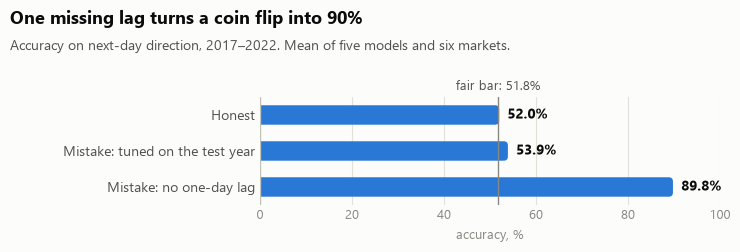

In [9]:
means = summary.loc["mean of the five models"]
fig, ax = new_chart("One missing lag turns a coin flip into 90%",
                    "Accuracy on next-day direction, 2017–2022. Mean of five models and six markets.",
                    ["Honest", "Mistake: tuned on the test year", "Mistake: no one-day lag"], "accuracy, %", left=2.7)
bars(ax, means, [f"{value:.1f}%" for value in means], x_max=100)
reference_line(ax, fair_bar.mean(), f"fair bar: {fair_bar.mean():.1f}%")
save(fig, "mistakes.png")

## What this shows

- **Forgetting the lag takes every model from about 52% to 84-93%.** All 30 model-market pairs then "beat" the fair bar significantly. One indicator alone, the A/D oscillator, scores 86%.
- **Tuning on the test year adds 1.9 points on average** (0.3 to 3.8 across the 30 pairs). That's enough to make 8 of the 30 pairs look significantly better than the fair bar. The honest version has none.
- **The big mistake is the easy one to catch.** 90% is suspicious on sight, and the leakage test fails.
- **The small one is the dangerous one.** 54% looks like a modest, believable edge, and no test of the features can catch it. Only the fold design does: settings are picked on the tune year, which comes before the test year.
- **This doesn't show that any particular paper forgot the lag.** It shows that scores of 60-90% are what these mistakes produce, so a high score needs a leakage check before it's believed.